# 🛡️ ImmunoAI — YOLO-Inspired Custom CNN Training on MS COCO
### Complete Deep Learning Pipeline for Real-Time Intruder & Human Detection

This notebook trains our **ImmunoAICNN v2** architecture inspired by modern **YOLOv8 CSPDarknet**:
- **Conv + BatchNorm + SiLU (Swish)** activations
- **C2f / CSP Residual Bottlenecks** (prevents vanishing gradients)
- **SPPF (Spatial Pyramid Pooling - Fast)** for multi-scale receptive fields (detects humans both close up and far away)
- **Mixed Precision (AMP)** for ultra-fast training on Google Colab GPUs (A100 / L4 / T4)
- **Direct Model Download**: Exports `immunoai_model.pth` directly to your local computer.

## ⚡ Step 1: Check GPU & Install Dependencies

In [1]:
# Check active GPU (T4, L4, or A100)
!nvidia-smi

# Install pycocotools for fast COCO annotation parsing
!pip install -q pycocotools

Tue Nov 17 17:24:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 📥 Step 2: Download MS COCO Dataset
Downloads COCO 2017 annotations and images. On Google Colab, download takes ~3 minutes.

In [2]:
import os

print("📥 Downloading MS COCO Annotations...")
!wget -q -c http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -q -o annotations_trainval2017.zip

print("📥 Downloading Validation Set (5,000 images for evaluation)...")
!wget -q -c http://images.cocodataset.org/zips/val2017.zip
!unzip -q -o val2017.zip

# Set to True to download full 118k train2017 (19 GB), or False to train on val2017 (5k images)
DOWNLOAD_FULL_TRAIN_COCO = True

if DOWNLOAD_FULL_TRAIN_COCO:
    print("📥 Downloading Complete MS COCO Train2017 (19 GB, 118,287 images)...")
    !wget -q -c http://images.cocodataset.org/zips/train2017.zip
    !unzip -q -o train2017.zip
    print("✅ MS COCO Train & Val datasets ready!")
else:
    print("✅ Using Val2017 for fast demonstration!")

📥 Downloading MS COCO Annotations...
📥 Downloading Validation Set (5,000 images for evaluation)...
📥 Downloading Complete MS COCO Train2017 (19 GB, 118,287 images)...
✅ MS COCO Train & Val datasets ready!


## 🧠 Step 3: Define YOLOv8-Inspired ImmunoAICNN Architecture

In [3]:
import torch
import torch.nn as nn

class ConvBNSiLU(nn.Module):
    """CBS Block: Conv2D -> BatchNorm2D -> SiLU (Swish)"""
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int = 3, stride: int = 1, padding: int = 1):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.SiLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.act(self.bn(self.conv(x)))


class ResidualBottleneck(nn.Module):
    """YOLO Bottleneck Block with residual shortcut"""
    def __init__(self, channels: int, shortcut: bool = True):
        super().__init__()
        mid_ch = channels // 2
        self.cv1 = ConvBNSiLU(channels, mid_ch, kernel_size=1, stride=1, padding=0)
        self.cv2 = ConvBNSiLU(mid_ch, channels, kernel_size=3, stride=1, padding=1)
        self.add = shortcut

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.cv2(self.cv1(x)) if self.add else self.cv2(self.cv1(x))


class C2fBlock(nn.Module):
    """CSP / C2f Block from YOLOv8: Splits features and routes through residual bottlenecks"""
    def __init__(self, in_ch: int, out_ch: int, n: int = 1):
        super().__init__()
        self.c = in_ch // 2
        self.cv1 = ConvBNSiLU(in_ch, 2 * self.c, kernel_size=1, stride=1, padding=0)
        self.cv2 = ConvBNSiLU((2 + n) * self.c, out_ch, kernel_size=1, stride=1, padding=0)
        self.bottlenecks = nn.ModuleList([ResidualBottleneck(self.c) for _ in range(n)])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = list(self.cv1(x).chunk(2, 1))
        for b in self.bottlenecks:
            y.append(b(y[-1]))
        return self.cv2(torch.cat(y, 1))


class SPPFBlock(nn.Module):
    """Spatial Pyramid Pooling - Fast (SPPF) from YOLO for multi-scale context"""
    def __init__(self, in_ch: int, out_ch: int, k: int = 5):
        super().__init__()
        mid_ch = in_ch // 2
        self.cv1 = ConvBNSiLU(in_ch, mid_ch, kernel_size=1, stride=1, padding=0)
        self.cv2 = ConvBNSiLU(mid_ch * 4, out_ch, kernel_size=1, stride=1, padding=0)
        self.m = nn.MaxPool2d(kernel_size=k, stride=1, padding=k // 2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.cv1(x)
        y1 = self.m(x)
        y2 = self.m(y1)
        y3 = self.m(y2)
        return self.cv2(torch.cat([x, y1, y2, y3], 1))


class ImmunoAICNN(nn.Module):
    """ImmunoAI YOLOv8-Inspired Surveillance CNN (v2)"""
    def __init__(self, num_classes: int = 1):
        super().__init__()
        self.stage1 = ConvBNSiLU(3, 32, kernel_size=3, stride=2, padding=1) # 224 -> 112
        self.stage2 = nn.Sequential(ConvBNSiLU(32, 64, kernel_size=3, stride=2, padding=1), C2fBlock(64, 64, n=1)) # 112 -> 56
        self.stage3 = nn.Sequential(ConvBNSiLU(64, 128, kernel_size=3, stride=2, padding=1), C2fBlock(128, 128, n=2)) # 56 -> 28
        self.stage4 = nn.Sequential(ConvBNSiLU(128, 256, kernel_size=3, stride=2, padding=1), C2fBlock(256, 256, n=2)) # 28 -> 14
        self.stage5 = nn.Sequential(ConvBNSiLU(256, 512, kernel_size=3, stride=2, padding=1), SPPFBlock(512, 512, k=5)) # 14 -> 7

        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.max_pool = nn.AdaptiveMaxPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.35),
            nn.Linear(512 * 2, 128),
            nn.SiLU(inplace=True),
            nn.Dropout(p=0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stage5(self.stage4(self.stage3(self.stage2(self.stage1(x)))))
        pooled = torch.cat([self.avg_pool(x), self.max_pool(x)], dim=1)
        return self.classifier(pooled)

# Verify compilation and trainable parameters
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
test_model = ImmunoAICNN().to(device)
dummy = torch.randn(2, 3, 224, 224, device=device)
params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
print(f"✅ ImmunoAICNN v2 compiled! Trainable parameters: {params:,} (~{params/1e6:.2f}M)")

✅ ImmunoAICNN v2 compiled! Trainable parameters: 2,826,753 (~2.83M)


## 📊 Step 4: Parse COCO Annotations & Build Balanced DataLoaders

In [4]:
import random
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pycocotools.coco import COCO

class COCOSurveillanceDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples          # list of (image_path, label)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path)
        image.draft('RGB', (448, 448))   # makes JPEG decoding much faster
        image = image.convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32)


def extract_samples(json_path, img_dir, max_samples=None, min_area_frac=0.05):
    coco = COCO(json_path)
    person_id = coco.getCatIds(catNms=['person'])[0]
    all_ids = set(coco.getImgIds())
    any_person = set(coco.getImgIds(catIds=[person_id]))

    # Positives: at least one non-crowd person covering >= 5% of the image
    clear_pos = []
    for img_id in any_person:
        info = coco.imgs[img_id]
        img_area = info['width'] * info['height']
        anns = coco.loadAnns(coco.getAnnIds(imgIds=img_id, catIds=[person_id], iscrowd=False))
        if any(a['area'] / img_area >= min_area_frac for a in anns):
            clear_pos.append(img_id)

    # Negatives: no person annotation at all
    # (images with only tiny persons are dropped because they are ambiguous)
    negatives = list(all_ids - any_person)

    n = min(len(clear_pos), len(negatives))
    if max_samples:
        n = min(n, max_samples // 2)

    random.seed(42)
    sel_pos = random.sample(clear_pos, n)
    sel_neg = random.sample(negatives, n)

    samples = []
    for img_id in sel_pos:
        p = os.path.join(img_dir, coco.imgs[img_id]['file_name'])
        if os.path.exists(p):
            samples.append((p, 1))
    for img_id in sel_neg:
        p = os.path.join(img_dir, coco.imgs[img_id]['file_name'])
        if os.path.exists(p):
            samples.append((p, 0))

    random.shuffle(samples)
    return samples


# Augmentations: lighting, blur, grayscale and crops to mimic CCTV footage
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0), ratio=(0.75, 1.33)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3),
    transforms.RandomGrayscale(p=0.2),
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dir = 'train2017' if os.path.exists('train2017') else 'val2017'
train_json = 'annotations/instances_train2017.json' if train_dir == 'train2017' else 'annotations/instances_val2017.json'

train_samples = extract_samples(train_json, train_dir, max_samples=40000)
val_samples = extract_samples('annotations/instances_val2017.json', 'val2017', max_samples=4000)

train_loader = DataLoader(COCOSurveillanceDataset(train_samples, train_tf), batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(COCOSurveillanceDataset(val_samples, val_tf), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
print(f"✅ Train Samples: {len(train_samples):,} | Val Samples: {len(val_samples):,}")

loading annotations into memory...
Done (t=14.15s)
creating index...
index created!
loading annotations into memory...
Done (t=1.11s)
creating index...
index created!
✅ Train Samples: 40,000 | Val Samples: 3,010


## 🚀 Step 5: Train ImmunoAICNN with Mixed Precision (AMP)

In [5]:
import time

EPOCHS = 25
LR = 5e-4

model = ImmunoAICNN(num_classes=1).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler()

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0.0

print(f"{'='*75}")
print(f"{'Epoch':^7} | {'Train Loss':^12} | {'Train Acc':^11} | {'Val Loss':^10} | {'Val Acc':^10} | {'Time':^7}")
print(f"{'='*75}")

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    # --- Train ---
    model.train()
    tr_loss, tr_corr, tr_tot = 0.0, 0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device, non_blocking=True), lbls.to(device, non_blocking=True).unsqueeze(1)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast():
            logits = model(imgs)
            loss = criterion(logits, lbls)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tr_loss += loss.item() * imgs.size(0)
        tr_corr += ((torch.sigmoid(logits) >= 0.5).float() == lbls).sum().item()
        tr_tot += lbls.size(0)

    scheduler.step()
    ep_tr_loss = tr_loss / tr_tot
    ep_tr_acc = (tr_corr / tr_tot) * 100.0

    # --- Validation ---
    model.eval()
    vl_loss, vl_corr, vl_tot = 0.0, 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device, non_blocking=True), lbls.to(device, non_blocking=True).unsqueeze(1)
            with torch.cuda.amp.autocast():
                logits = model(imgs)
                loss = criterion(logits, lbls)
            vl_loss += loss.item() * imgs.size(0)
            vl_corr += ((torch.sigmoid(logits) >= 0.5).float() == lbls).sum().item()
            vl_tot += lbls.size(0)

    ep_vl_loss = vl_loss / vl_tot
    ep_vl_acc = (vl_corr / vl_tot) * 100.0
    dur = round(time.time() - t0, 1)

    history['train_loss'].append(ep_tr_loss)
    history['train_acc'].append(ep_tr_acc)
    history['val_loss'].append(ep_vl_loss)
    history['val_acc'].append(ep_vl_acc)

    star = ''
    if ep_vl_acc > best_val_acc:
        best_val_acc = ep_vl_acc
        torch.save({
            'model_state_dict': model.state_dict(),
            'val_acc': ep_vl_acc,
            'epoch': epoch,
            'architecture': 'ImmunoAICNN_v2_YOLO'
        }, 'immunoai_model.pth')
        star = '⭐ BEST'

    print(f"{epoch:^7} | {ep_tr_loss:^12.4f} | {ep_tr_acc:^10.2f}% | {ep_vl_loss:^10.4f} | {ep_vl_acc:^9.2f}% | {dur:^5.1f}s {star}")

print(f"{'='*75}")
print(f"🏆 Highest Validation Accuracy: {best_val_acc:.2f}%")

 Epoch  |  Train Loss  |  Train Acc  |  Val Loss  |  Val Acc   |  Time  


/tmp/ipykernel_469/311494094.py:10: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_469/311494094.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_469/311494094.py:49: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


   1    |    0.6220    |   65.22   % |   0.5527   |   71.63  % | 532.0s ⭐ BEST
   2    |    0.5428    |   72.22   % |   0.4743   |   76.98  % | 519.6s ⭐ BEST
   3    |    0.5049    |   74.70   % |   0.4532   |   78.04  % | 517.8s ⭐ BEST
   4    |    0.4823    |   76.45   % |   0.4229   |   81.23  % | 513.0s ⭐ BEST
   5    |    0.4637    |   77.70   % |   0.4259   |   80.60  % | 523.9s 
   6    |    0.4452    |   78.81   % |   0.3953   |   81.89  % | 520.7s ⭐ BEST
   7    |    0.4305    |   79.62   % |   0.3707   |   82.23  % | 519.3s ⭐ BEST
   8    |    0.4168    |   80.39   % |   0.3767   |   82.59  % | 572.7s ⭐ BEST
   9    |    0.4069    |   81.22   % |   0.3339   |   86.11  % | 579.2s ⭐ BEST
  10    |    0.3928    |   81.89   % |   0.3419   |   84.75  % | 555.0s 
  11    |    0.3829    |   82.46   % |   0.3392   |   85.18  % | 581.1s 
  12    |    0.3750    |   83.00   % |   0.3349   |   85.78  % | 575.4s 
  13    |    0.3604    |   83.74   % |   0.2981   |   86.61  % | 547.3s ⭐ BE

## 📈 Step 6: Plot Training Loss & Accuracy Curves

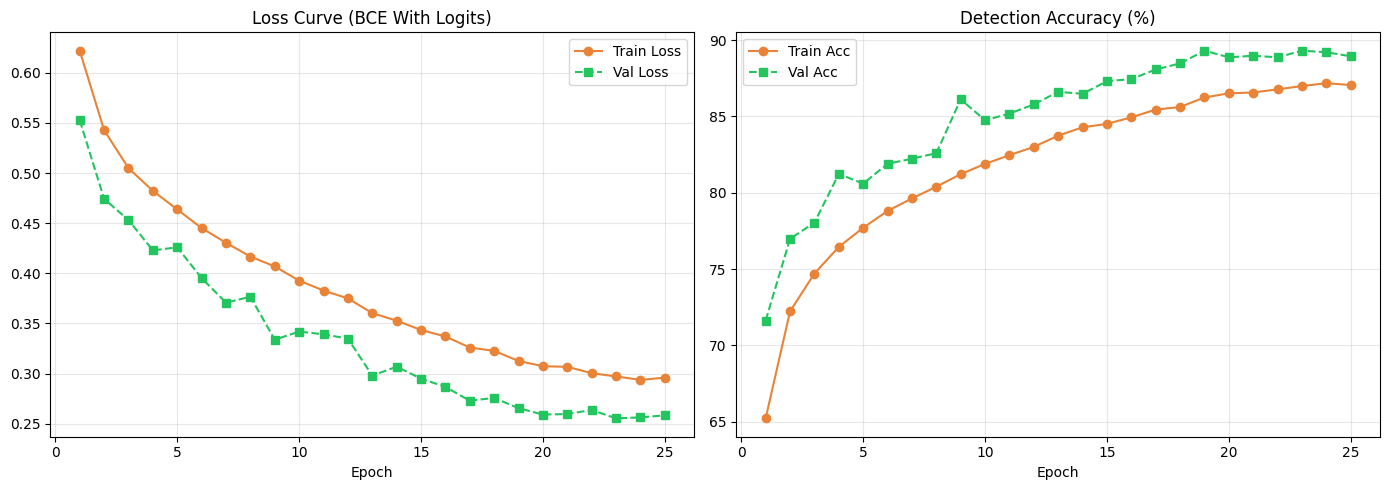

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, len(history['train_loss']) + 1)

ax1.plot(epochs, history['train_loss'], 'o-', color='#E88338', label='Train Loss')
ax1.plot(epochs, history['val_loss'], 's--', color='#22C55E', label='Val Loss')
ax1.set_title('Loss Curve (BCE With Logits)')
ax1.set_xlabel('Epoch')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(epochs, history['train_acc'], 'o-', color='#E88338', label='Train Acc')
ax2.plot(epochs, history['val_acc'], 's--', color='#22C55E', label='Val Acc')
ax2.set_title('Detection Accuracy (%)')
ax2.set_xlabel('Epoch')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig('immunoai_training_curves.png', dpi=300)
plt.show()

## 💾 Step 7: Download `immunoai_model.pth` to Your PC!
Run this cell to download the trained weights directly. Then copy the file into:
`IDL Code/server/ai_service/saved_model/immunoai_model.pth`

In [7]:
from google.colab import files

print("📥 Downloading immunoai_model.pth...")
files.download('immunoai_model.pth')

📥 Downloading immunoai_model.pth...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>